# LAB 10 — K-Means Clustering
## Finding Customer Segments, Choosing K and Avoiding the Traps on Real Data

## Student Information
- **Name:Salma**
- **Student ID:023-24-0173**
- **Section:F**
- **GitHub:https://github.com/SalmaLatki/MLlab10-.git**
- **Kaggle:https://www.kaggle.com/code/salmalatki/mllaab10-023-24-0173**
- **Dataset:** Mall Customers (Kaggle) + Wine (UCI)
- **Dataset Source:** https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python and https://archive.ics.uci.edu/dataset/109/wine

### Before You Start
- You studied K-Means in the lecture. This notebook does not teach it again; it makes you use it, test it and question it.
- There is **no target column**: no train/test split and no accuracy. Judge results by distances, silhouette, plots and common sense.
- Use `SEED = 42`. Write an interpretation under every table and plot. Place `Mall_Customers.csv` in the same folder as this notebook.
- `from sklearn.datasets import load_wine` loads the Wine data (no download needed).


---

## Part 0 — Setup and First Look (10 minutes)

Today there is no target column. The Mall Customers data has no 'right answer' for each customer, so we do not split into train and test and we cannot use accuracy. You will find groups with K-Means (your lecture) and judge them by distance, silhouette and common sense.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Unsupervised learning | Learning from data that has no labels. The goal is to find structure (groups), not to predict a column. | `No y, no train_test_split.` |
| Cluster | A group of points that are close to each other and far from the other groups. | `model.labels_ gives the cluster number of every row.` |
| Feature | One column used to describe each row (here Age, Income, Spending). | `df[['Income','Spending']].values` |


**First cell:** import everything you need (NumPy, Pandas, Matplotlib, KMeans, StandardScaler, PCA, load_wine, silhouette_score, silhouette_samples, adjusted_rand_score) and set `SEED = 42`.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.datasets import load_wine
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
SEED = 42


### Task 0.1 — Load and check the data

Load Mall_Customers.csv and understand it in one cell.

1. Load the CSV. Rename 'Annual Income (k$)' to Income and 'Spending Score (1-100)' to Spending (shorter names).
2. Print the shape, the number of missing values, the number of duplicate rows and the count of each Gender.
3. Show describe() for Age, Income and Spending.


In [ ]:
df = pd.read_csv('Mall_Customers.csv')
df = df.rename(columns={'Annual Income (k$)':'Income','Spending Score (1-100)':'Spending'})
print('shape:', df.shape)
print('missing:', df.isnull().sum().sum())
print('duplicates:', df.duplicated().sum())
print(df['Gender'].value_counts())
print(df[['Age','Income','Spending']].describe())


shape: (200, 5)
missing: 0
duplicates: 0
Gender
Female    112
Male       88
Name: count, dtype: int64
              Age      Income    Spending
count  200.000000  200.000000  200.000000
mean    38.850000   60.560000   50.200000
std     13.969007   26.264721   25.823522
min     18.000000   15.000000    1.000000
25%     28.750000   41.500000   34.750000
50%     36.000000   61.500000   50.000000
75%     49.000000   78.000000   73.000000
max     70.000000  137.000000   99.000000


### Task 0.2 — Look at the data before clustering

Use your eyes first: draw three scatter plots side by side.

1. Draw Spending vs Income, Spending vs Age and Income vs Age (one row of three plots, axis labels and titles).


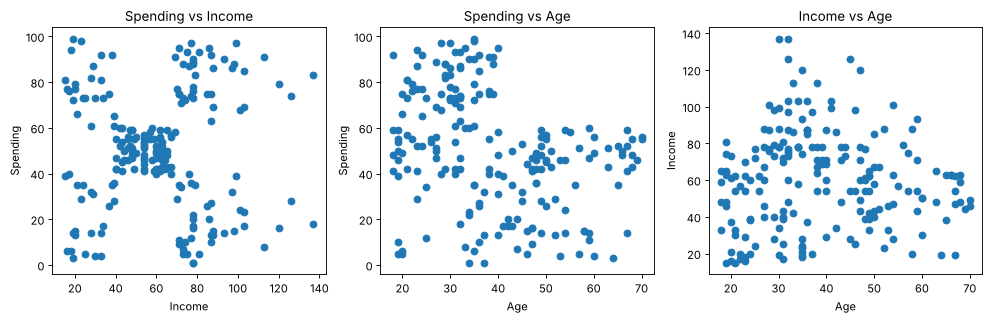

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15,4))
ax[0].scatter(df['Income'], df['Spending']); ax[0].set_xlabel('Income'); ax[0].set_ylabel('Spending'); ax[0].set_title('Spending vs Income')
ax[1].scatter(df['Age'], df['Spending']); ax[1].set_xlabel('Age'); ax[1].set_ylabel('Spending'); ax[1].set_title('Spending vs Age')
ax[2].scatter(df['Age'], df['Income']); ax[2].set_xlabel('Age'); ax[2].set_ylabel('Income'); ax[2].set_title('Income vs Age')
plt.show()


**Questions** (answer with your own numbers)

(a) How many groups can you see by eye in each of the three plots? Which plot shows the groups most clearly?

(b) Why can we not use accuracy or a train/test split to judge a clustering result?



Your answers:

(a) Spending vs Income shows 5 clear groups (4 corners and 1 in the middle). Spending vs Age shows maybe 2-3 loose groups and Income vs Age shows no clear groups. So Spending vs Income is the clearest.

(b) We have no true label for each customer, so there is nothing to compare the result with and no accuracy. There is also no y to predict, so train/test split has no meaning.


---

## Part 1 — K-Means From Scratch (35 minutes)

In the lecture you did K-Means by hand. Here you turn your pen-and-paper steps into code, check your answers against the lecture slides, and then build your own K-Means function and compare it with scikit-learn. Using KMeans() inside your own function is not allowed.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| K | The number of clusters. You choose it before running. | `KMeans(n_clusters=5)` |
| Centroid | The centre (mean) of a cluster. It is a point, not always a real row. | `model.cluster_centers_` |
| Distance | 1 feature: |x - m|. 2 or more features: Euclidean, sqrt of the sum of squared differences. | `np.abs(a-b)  or  np.sqrt(((a-b)**2).sum(axis=1))` |
| Assign step | Give each point to its nearest centroid. | `d.argmin(axis=1)` |
| Update step | Move each centroid to the mean of the points assigned to it. | `X[labels==k].mean(axis=0)` |
| Convergence | Stop when no point changes cluster (centroids stop moving). | `np.allclose(new_c, c)` |
| Inertia | Sum of squared distances from every point to its own centroid. Smaller = tighter clusters. | `model.inertia_` |
| Broadcasting | NumPy trick: x[:, None] - m[None, :] gives every point-to-centroid difference in one line. | `x[:, None, :] - C[None, :, :]` |


### Task 1.1 — Lecture Example 1 in code (one feature)

Reproduce the 9-number example from the lecture (2, 4, 10, 12, 3, 20, 30, 11, 25) with K = 2 and starting centroids 4 and 11.

1. Write a loop that, in every iteration, computes the distances, assigns the clusters, updates the centroids and prints both clusters and the new centroids.
2. Stop when no centroid changes. Print the final centroids and the inertia.
3. Compare with the lecture slides (final centroids 7 and 25, inertia 150).

**Hints:**
- Distance matrix: np.abs(x[:, None] - m[None, :]) has shape (9, 2).
- Cluster of each point: dist.argmin(axis=1).


In [ ]:
x = np.array([2,4,10,12,3,20,30,11,25])
c = np.array([4.,11.])
it = 0
while True:
    it += 1
    dist = np.abs(x[:, None] - c[None, :])
    lab = dist.argmin(axis=1)
    new_c = np.array([x[lab==k].mean() for k in range(2)])
    print('iter', it, 'C1:', x[lab==0], 'C2:', x[lab==1], 'new centroids:', new_c)
    if np.allclose(new_c, c):
        break
    c = new_c
inertia = ((x - c[lab])**2).sum()
print('final centroids:', c, 'inertia:', inertia)


iter 1 C1: [2 4 3] C2: [10 12 20 30 11 25] new centroids: [ 3. 18.]
iter 2 C1: [ 2  4 10  3] C2: [12 20 30 11 25] new centroids: [ 4.75 19.6 ]
iter 3 C1: [ 2  4 10 12  3 11] C2: [20 30 25] new centroids: [ 7. 25.]
iter 4 C1: [ 2  4 10 12  3 11] C2: [20 30 25] new centroids: [ 7. 25.]
final centroids: [ 7. 25.] inertia: 150.0


### Task 1.2 — Lecture Example 2 in code (two features)

Do the height/weight example: P1 (185, 72), P2 (170, 56), P3 (168, 60), P4 (179, 68), P5 (182, 72), P6 (188, 77). K = 2, start with P1 and P2.

1. Use Euclidean distance and the same loop idea. Print the cluster of every point and the centroids per iteration.
2. Print the final distance table and check one value by hand (the lecture shows d(P3, M2) = 4.47 in the first iteration).


In [ ]:
P = np.array([[185,72],[170,56],[168,60],[179,68],[182,72],[188,77]], dtype=float)
M = P[[0,1]].copy()
it = 0
first = None
while True:
    it += 1
    dist = np.sqrt(((P[:, None, :] - M[None, :, :])**2).sum(axis=2))
    if first is None:
        first = dist.copy()
    lab = dist.argmin(axis=1)
    new_M = np.array([P[lab==k].mean(axis=0) for k in range(2)])
    print('iter', it, 'clusters:', lab+1, 'centroids:', new_M.round(2).tolist())
    if np.allclose(new_M, M):
        break
    M = new_M
print(pd.DataFrame(dist.round(2), index=['P1','P2','P3','P4','P5','P6'], columns=['M1','M2']))
print('d(P3,M2) first iteration =', first[2,1].round(2))


iter 1 clusters: [1 2 2 1 1 1] centroids: [[183.5, 72.25], [169.0, 58.0]]
iter 2 clusters: [1 2 2 1 1 1] centroids: [[183.5, 72.25], [169.0, 58.0]]
       M1     M2
P1   1.52  21.26
P2  21.13   2.24
P3  19.76   2.24
P4   6.19  14.14
P5   1.52  19.10
P6   6.54  26.87
d(P3,M2) first iteration = 4.47


### Task 1.3 — Write your own K-Means function

Write my_kmeans(X, init_centroids, max_iter=100) for any number of features.

1. Return four things: labels, final centroids, inertia and the number of iterations.
2. Test it on Example 1: it must give centroids 7 and 25 and inertia 150.
3. Think about what to do if a cluster ends up empty (keep its old centroid).


In [ ]:
def my_kmeans(X, init_centroids, max_iter=100):
    X = np.asarray(X, dtype=float)
    if X.ndim == 1:
        X = X.reshape(-1, 1)
    C = np.asarray(init_centroids, dtype=float).reshape(len(init_centroids), -1).copy()
    K = len(C)
    old_labels = None
    for i in range(max_iter):
        d = np.sqrt(((X[:, None, :] - C[None, :, :])**2).sum(axis=2))
        labels = d.argmin(axis=1)
        new_C = C.copy()
        for k in range(K):
            if (labels == k).sum() > 0:   # empty cluster keeps old centroid
                new_C[k] = X[labels == k].mean(axis=0)
        C = new_C
        if old_labels is not None and np.array_equal(labels, old_labels):
            break
        old_labels = labels
    inertia = ((X - C[labels])**2).sum()
    return labels, C, inertia, i + 1


In [ ]:
l, cc, inn, n = my_kmeans(x, [4, 11])
print('labels:', l, 'centroids:', cc.ravel(), 'inertia:', inn, 'iterations:', n)


labels: [0 0 0 0 0 1 1 0 1] centroids: [ 7. 25.] inertia: 150.0 iterations: 4


### Task 1.4 — Check your function against scikit-learn

Run your function and KMeans on the same data with the same starting centroids and compare.

1. Use X2 = Income and Spending (200 x 2). Take the first 5 rows as the starting centroids.
2. Run my_kmeans. Run KMeans(n_clusters=5, init=<your 5 rows>, n_init=1, tol=0, algorithm='lloyd').
3. Compare iterations, inertia, labels and centroids.


In [ ]:
X2 = df[['Income','Spending']].values.astype(float)
init = X2[:5].copy()
l1, c1, in1, n1 = my_kmeans(X2, init)
sk = KMeans(n_clusters=5, init=init, n_init=1, tol=0, algorithm='lloyd').fit(X2)
print('iterations  mine:', n1, ' sklearn:', sk.n_iter_)
print('inertia     mine:', round(in1,4), ' sklearn:', round(sk.inertia_,4))
print('labels same:', np.array_equal(l1, sk.labels_), ' ARI:', adjusted_rand_score(l1, sk.labels_))
print('centroids same:', np.allclose(c1, sk.cluster_centers_))
print(c1.round(2))


iterations  mine: 4  sklearn: 4
inertia     mine: 44448.4554  sklearn: 44448.4554
labels same: True  ARI: 1.0
centroids same: True
[[26.3  20.91]
 [25.73 79.36]
 [88.2  17.11]
 [86.54 82.13]
 [55.3  49.52]]


**Questions** (answer with your own numbers)

(a) Example 1: the point 10 started in cluster C2 but moved to C1 in iteration 2. Explain why, using the centroid values.

(b) What makes the loop stop? Why is the stopping guaranteed even though the final answer is not always the best one?

(c) Did your function match scikit-learn exactly (labels, centroids, inertia)? If anything differed, explain why.

(d) What does a centroid mean for a group of customers? Why must the features be numeric for K-Means?



Your answers:

(a) After iteration 1 the centroids were C1 = 3 and C2 = 18. Point 10 is 7 away from 3 but 8 away from 18, so it is closer to C1 and moves there.

(b) It stops when no point changes cluster, so the centroids stop moving. Every step only lowers or keeps the inertia and there are only a limited number of ways to assign points, so it must stop, but it can stop at a local minimum and not the best answer.

(c) Yes, it matched exactly. Both took 4 iterations, inertia 44448.46, labels are the same (ARI = 1) and centroids are the same, because the start points and the rule are the same.

(d) A centroid is the average customer of the group, for example about 88k income and 17 spending. K-Means needs numbers because it takes distances and means, which cannot be done on text.


---

## Part 2 — Choosing K: Elbow and Silhouette (30 minutes)

The algorithm needs K before it starts, but nobody tells us K. The lecture gave two tools: the elbow (inertia) and the silhouette score. Here you use both, then calculate a silhouette by hand to prove you understand it.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Elbow method | Plot inertia for K = 2, 3, 4 ... Inertia always falls as K grows, so look for the K where the fall suddenly becomes small (the bend). | `model.inertia_ in a loop over K` |
| a | Average distance from a point to the other points in its own cluster (smaller = better). | `d[same_cluster].mean()` |
| b | Average distance from the point to the points of the nearest other cluster (larger = better). | `min over other clusters` |
| Silhouette s | s = (b - a) / max(a, b). Close to +1: well placed. Near 0: on the border. Negative: probably in the wrong cluster. | `silhouette_samples(X, labels)` |
| Average silhouette | The mean of s over all points. The K with the highest value is a good candidate. | `silhouette_score(X, labels)` |


### Task 2.1 — Elbow and silhouette for K = 2 to 10

Decide how many customer groups exist using Income and Spending (X2).

1. For K = 2 to 10 fit KMeans(n_clusters=K, n_init=10, random_state=SEED) and record the inertia and the average silhouette.
2. Show a table (K, Inertia, Silhouette) and two plots: elbow curve and silhouette bars.
3. Print the K with the highest silhouette.


 K     Inertia  Silhouette
 2 181363.5960      0.2969
 3 106348.3731      0.4676
 4  73679.7890      0.4932
 5  44448.4554      0.5539
 6  37233.8145      0.5398
 7  30241.3436      0.5288
 8  25036.4176      0.4548
 9  21916.7948      0.4561
10  20072.0709      0.4411
best K by silhouette: 5
inertia drop 4->5: 29231.3  5->6: 7214.6


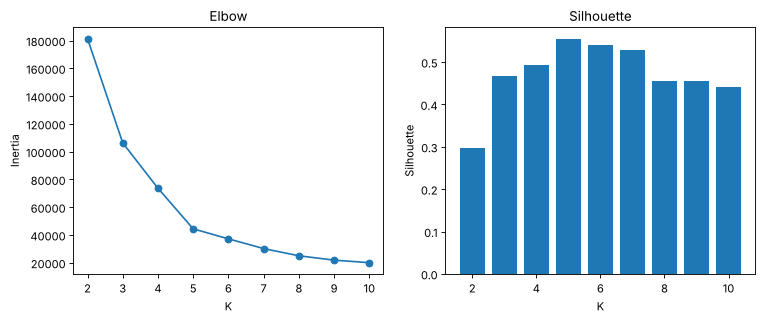

In [ ]:
rows = []
for k in range(2, 11):
    m = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X2)
    rows.append([k, m.inertia_, silhouette_score(X2, m.labels_)])
res = pd.DataFrame(rows, columns=['K','Inertia','Silhouette'])
print(res.round(4).to_string(index=False))
fig, ax = plt.subplots(1, 2, figsize=(11,4))
ax[0].plot(res['K'], res['Inertia'], 'o-'); ax[0].set_xlabel('K'); ax[0].set_ylabel('Inertia'); ax[0].set_title('Elbow')
ax[1].bar(res['K'], res['Silhouette']); ax[1].set_xlabel('K'); ax[1].set_ylabel('Silhouette'); ax[1].set_title('Silhouette')
plt.show()
print('best K by silhouette:', res.loc[res['Silhouette'].idxmax(), 'K'])
print('inertia drop 4->5:', round(res.Inertia[2]-res.Inertia[3],1), ' 5->6:', round(res.Inertia[3]-res.Inertia[4],1))


### Task 2.2 — Silhouette by hand

Prove that you understand the formula by calculating it yourself.

1. Fit K = 5. Write a function that returns a, b and s for one point (use only NumPy distances). Apply it to customer 1 (row 0) and compare with silhouette_samples.
2. Show the count, mean and minimum silhouette of every cluster, and the number of customers with a negative silhouette.
3. Draw a silhouette plot of all customers sorted inside each cluster.


In [ ]:
m5 = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
lab5 = m5.labels_

def sil_point(X, labels, i):
    d = np.sqrt(((X - X[i])**2).sum(axis=1))
    own = labels == labels[i]
    a = d[own].sum() / (own.sum() - 1)
    b = min(d[labels == k].mean() for k in np.unique(labels) if k != labels[i])
    s = (b - a) / max(a, b)
    return a, b, s

a, b, s = sil_point(X2, lab5, 0)
print('customer 1  a =', round(a,4), 'b =', round(b,4), 's =', round(s,4))
sk_s = silhouette_samples(X2, lab5)
print('silhouette_samples      =', round(sk_s[0],4))


customer 1  a = 24.6404 b = 42.2653 s = 0.417
silhouette_samples      = 0.417


         count    mean     min
Cluster                       
0           81  0.5967  0.1153
1           39  0.5092  0.2254
2           22  0.5990  0.0507
3           35  0.5040 -0.0234
4           23  0.5123 -0.0093
negative silhouette: 2


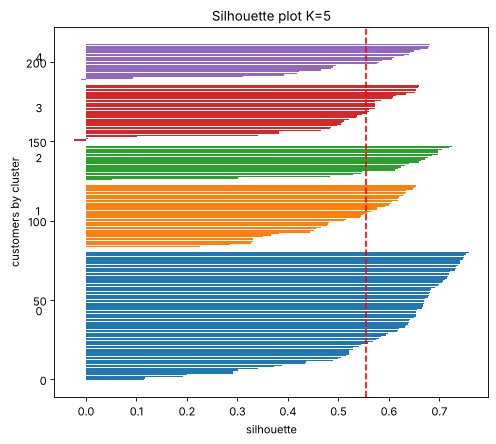

In [ ]:
t = pd.DataFrame({'Cluster': lab5, 's': sk_s}).groupby('Cluster')['s'].agg(['count','mean','min'])
print(t.round(4))
print('negative silhouette:', (sk_s < 0).sum())

fig, ax = plt.subplots(figsize=(7,6))
y = 0
for k in range(5):
    v = np.sort(sk_s[lab5 == k])
    ax.barh(range(y, y+len(v)), v)
    ax.text(-0.1, y + len(v)/2, str(k))
    y += len(v) + 3
ax.axvline(sk_s.mean(), color='red', ls='--')
ax.set_xlabel('silhouette'); ax.set_ylabel('customers by cluster'); ax.set_title('Silhouette plot K=5')
plt.show()


### Task 2.3 — The lecture practice problem

Points 1, 3, 5, 7, 11, 13, 15 with K = 2 and starting centroids 1 and 11 (the 'Practice' slide).

1. Run your my_kmeans on these points and print the final clusters, centroids and iterations.
2. Calculate a, b and s for the points 1, 7 and 11 with your function and compare with silhouette_samples.
3. Also write the iterations on paper (clusters and centroids after each iteration) and keep the photo or notes for your own revision.


In [ ]:
pts = np.array([1,3,5,7,11,13,15])
lp, cp, ip, npp = my_kmeans(pts, [1, 11])
for k in range(2):
    print('cluster', k+1, pts[lp==k])
print('centroids:', cp.ravel(), 'inertia:', ip, 'iterations:', npp)
Xp = pts.reshape(-1,1).astype(float)
sp = silhouette_samples(Xp, lp)
for p in [1, 7, 11]:
    i = list(pts).index(p)
    a, b, s = sil_point(Xp, lp, i)
    print('point', p, 'a =', round(a,3), 'b =', round(b,3), 's =', round(s,3), ' sklearn s =', round(sp[i],3))


cluster 1 [1 3 5 7]
cluster 2 [11 13 15]
centroids: [ 4. 13.] inertia: 28.0 iterations: 3
point 1 a = 4.0 b = 12.0 s = 0.667  sklearn s = 0.667
point 7 a = 4.0 b = 6.0 s = 0.333  sklearn s = 0.333
point 11 a = 3.0 b = 7.0 s = 0.571  sklearn s = 0.571


**Questions** (answer with your own numbers)

(a) Which K does the elbow suggest and which K does the silhouette suggest? Do they agree? Quote the numbers (for example how much the inertia drops from K=4 to 5 and from 5 to 6).

(b) What is the silhouette of customer 1 and what does it tell you? Which cluster has the weakest average silhouette and how many customers have a negative value?

(c) In the practice problem, is point 1 or point 7 less well placed? Explain using a and b.

(d) Why should we never choose K only by the lowest inertia?



Your answers:

(a) Elbow suggests K = 5, because inertia drops 29231 from K=4 to 5 but only 7215 from K=5 to 6. Silhouette is also highest at K = 5 (0.5539), so they agree.

(b) Customer 1 has a = 24.64, b = 42.27 and s = 0.417, so it is placed okay but not very strongly. The weakest cluster is cluster 3 (mean 0.504) and 2 customers have a negative silhouette.

(c) Point 7 is less well placed. Point 1 has a = 4, b = 12 (s = 0.667) but point 7 has a = 4, b = 6 (s = 0.333), so it is closer to the border of the other cluster.

(d) Inertia always goes down when K goes up, and it becomes 0 when K = number of points. So the lowest inertia would just give too many useless clusters.


---

## Part 3 — Starting Points and Stability (20 minutes)

The lecture said 'starting points matter - run several starts and keep the best'. You will now measure how much, using the same data and the same K.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Local minimum | A solution that cannot be improved by the assign/update loop but is not the best possible one. | `A higher final inertia than the best run.` |
| init='random' | Pick K random rows as the starting centroids. | `KMeans(init='random')` |
| init='k-means++' | Pick starting centroids that are far from each other. This is the default and is usually better. | `KMeans(init='k-means++')` |
| n_init | How many different starts to try. scikit-learn keeps the run with the lowest inertia. | `KMeans(n_init=10)` |
| Adjusted Rand Index (ARI) | Agreement between two groupings. 1 = same groups, about 0 = no better than random. It ignores the cluster numbers (cluster 2 in one run can be cluster 4 in another). | `adjusted_rand_score(a, b)` |


### Task 3.1 — 30 different seeds

Measure how often K-Means finds the best answer.

1. With K = 5 on X2, run KMeans 30 times (random_state = 0 to 29) in three settings: init='random' with n_init=1, k-means++ with n_init=1, k-means++ with n_init=10.
2. Build a table: setting, number of distinct final inertia values (round to 1 decimal), lowest, highest, and the percentage of runs that reached the best inertia.
3. Draw one histogram of the final inertia values for the three settings.


            Setting  Distinct  Lowest  Highest     % best
    random n_init=1        14 44448.5  91762.0  33.333333
 k-means++ n_init=1         6 44448.5  66733.4  60.000000
k-means++ n_init=10         1 44448.5  44448.5 100.000000


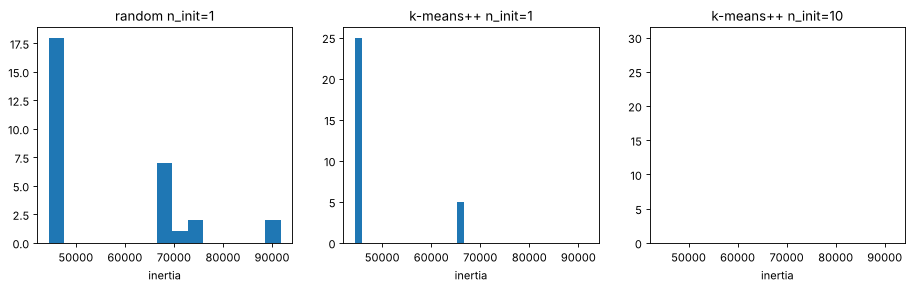

In [ ]:
settings = {'random n_init=1': dict(init='random', n_init=1),
            'k-means++ n_init=1': dict(init='k-means++', n_init=1),
            'k-means++ n_init=10': dict(init='k-means++', n_init=10)}
inert = {}
rand_models = []
for name, kw in settings.items():
    vals = []
    for sd in range(30):
        m = KMeans(n_clusters=5, random_state=sd, **kw).fit(X2)
        vals.append(m.inertia_)
        if name == 'random n_init=1':
            rand_models.append(m)
    inert[name] = np.array(vals)
best = min(v.min() for v in inert.values())
rows = []
for name, v in inert.items():
    r = np.round(v, 1)
    rows.append([name, len(np.unique(r)), r.min(), r.max(), 100*np.mean(r == round(best,1))])
print(pd.DataFrame(rows, columns=['Setting','Distinct','Lowest','Highest','% best']).to_string(index=False))
fig, ax = plt.subplots(1, 3, figsize=(14,3.5), sharex=True)
for a_, (name, v) in zip(ax, inert.items()):
    a_.hist(v, bins=15); a_.set_title(name); a_.set_xlabel('inertia')
plt.show()


### Task 3.2 — Best run vs worst run

See what a bad local minimum looks like.

1. From the random-init runs take the best and the worst. Draw both clusterings with their centroids side by side.
2. Print their inertia and their ARI.


best inertia: 44448.46 worst inertia: 91761.98
ARI best vs worst: 0.4553


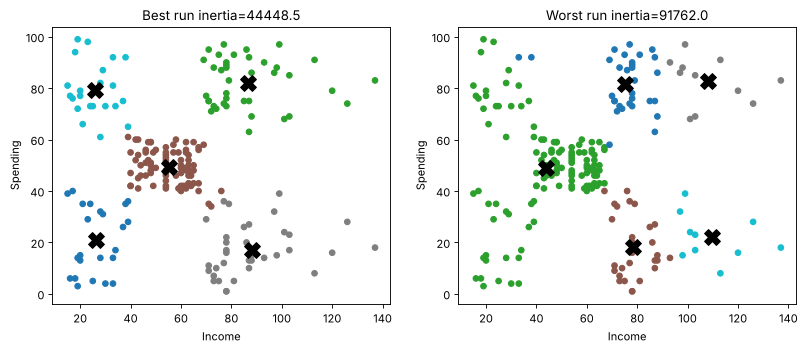

In [ ]:
iv = np.array([m.inertia_ for m in rand_models])
bm = rand_models[iv.argmin()]
wm = rand_models[iv.argmax()]
fig, ax = plt.subplots(1, 2, figsize=(12,4.5))
for a_, m, t in zip(ax, [bm, wm], ['Best run', 'Worst run']):
    a_.scatter(X2[:,0], X2[:,1], c=m.labels_, cmap='tab10', s=25)
    a_.scatter(m.cluster_centers_[:,0], m.cluster_centers_[:,1], c='black', marker='X', s=200)
    a_.set_title(t + ' inertia=' + str(round(m.inertia_,1))); a_.set_xlabel('Income'); a_.set_ylabel('Spending')
plt.show()
print('best inertia:', round(bm.inertia_,2), 'worst inertia:', round(wm.inertia_,2))
print('ARI best vs worst:', round(adjusted_rand_score(bm.labels_, wm.labels_),4))


**Questions** (answer with your own numbers)

(a) How many different final inertia values did the random-start setting produce, and what percentage of its runs reached the best one? Compare with the other two settings.

(b) Why can the same data and the same K give different answers?

(c) How do k-means++ and n_init help? What did n_init=10 give in your table?

(d) Why do we use ARI to compare two clusterings instead of comparing the label numbers directly?



Your answers:

(a) Random start gave 14 different inertia values and only 33.3% of runs reached the best (44448.5). k-means++ with n_init=1 gave 6 values and 60% best, and k-means++ with n_init=10 gave 1 value and 100% best.

(b) Because the starting centroids are different, and the loop can get stuck in a different local minimum each time.

(c) k-means++ picks starting centroids far from each other, so bad starts are less likely. n_init runs many starts and keeps the lowest inertia. With n_init=10 all 30 runs gave the same best inertia 44448.5.

(d) Cluster numbers are random (cluster 2 in one run can be cluster 4 in another), so comparing the numbers directly is wrong. ARI compares the groups and ignores the numbers.


---

## Part 4 — Scaling: Units Decide the Clusters (25 minutes)

The lecture warned: 'Rs 5000 would swamp 3 visits'. You will prove it twice: once by only changing the unit of Income, and once on the Wine data where the features have very different sizes and the true groups are known.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Feature scaling | Putting all features on a similar scale so that no feature wins the distance only because its numbers are bigger. | `StandardScaler().fit_transform(X)` |
| StandardScaler | z = (x - mean) / std. Every column gets mean 0 and standard deviation 1. | `StandardScaler()` |
| External check | Comparing clusters with known true groups. Possible only for teaching data like Wine. Real clustering problems have no labels. | `adjusted_rand_score(y_true, labels)` |
| PCA (Lab 8) | Reduces many features to 2 so we can draw the data. Used here only for the plot. | `PCA(n_components=2)` |


### Task 4.1 — Change the unit, change the clusters

Use Age and Income with K = 4. Income is in thousands of dollars (15 to 137). Make a second copy where Income is in dollars (multiply by 1000).

1. Cluster four versions: raw k$, raw dollars, scaled k$, scaled dollars (StandardScaler, n_init=10, random_state=SEED).
2. Print ARI between: raw k$ vs raw dollars, scaled k$ vs scaled dollars, raw dollars vs scaled dollars.
3. Draw Age vs Income (in k$) coloured by the clusters of raw k$, raw dollars and scaled.


ARI raw k$ vs raw $      : 0.4897
ARI scaled k$ vs scaled $: 1.0
ARI raw $ vs scaled $    : 0.3605


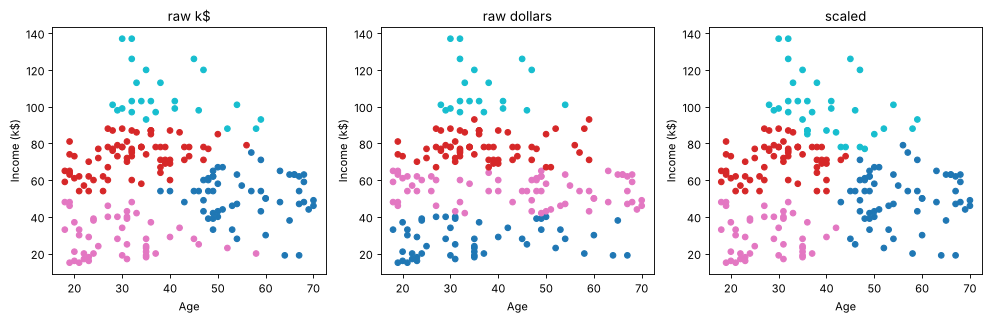

In [ ]:
A = df[['Age','Income']].values.astype(float)
Ad = A.copy(); Ad[:,1] = Ad[:,1] * 1000
def km4(X):
    return KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(X).labels_
l_raw = km4(A)
l_rawd = km4(Ad)
l_sc = km4(StandardScaler().fit_transform(A))
l_scd = km4(StandardScaler().fit_transform(Ad))
print('ARI raw k$ vs raw $      :', round(adjusted_rand_score(l_raw, l_rawd),4))
print('ARI scaled k$ vs scaled $:', round(adjusted_rand_score(l_sc, l_scd),4))
print('ARI raw $ vs scaled $    :', round(adjusted_rand_score(l_rawd, l_sc),4))
fig, ax = plt.subplots(1, 3, figsize=(15,4))
for a_, l, t in zip(ax, [l_raw, l_rawd, l_sc], ['raw k$', 'raw dollars', 'scaled']):
    a_.scatter(A[:,0], A[:,1], c=l, cmap='tab10', s=25)
    a_.set_xlabel('Age'); a_.set_ylabel('Income (k$)'); a_.set_title(t)
plt.show()


### Task 4.2 — Wine data: raw vs scaled

Load the Wine data with load_wine(): 178 wines, 13 chemical measurements, 3 true grape cultivars. The true cultivar is used ONLY to check the result, never to fit K-Means.

1. Print the three largest and the smallest standard deviation of the features.
2. Run KMeans(K=3, n_init=10, random_state=SEED) on the raw data and on the scaled data. For each report ARI against the true cultivar, silhouette score and cluster sizes.


In [ ]:
wine = load_wine()
Xw = wine.data
yw = wine.target
sd = Xw.std(axis=0)
order = np.argsort(sd)
print('3 largest std:')
for i in order[::-1][:3]:
    print('  ', wine.feature_names[i], round(sd[i],3))
print('smallest std:', wine.feature_names[order[0]], round(sd[order[0]],4))


3 largest std:
   proline 314.022
   magnesium 14.242
   alcalinity_of_ash 3.33
smallest std: nonflavanoid_phenols 0.1241


In [ ]:
Xws = StandardScaler().fit_transform(Xw)
mw_raw = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(Xw)
mw_sc = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(Xws)
for name, m, X in [('raw', mw_raw, Xw), ('scaled', mw_sc, Xws)]:
    print(name, 'ARI:', round(adjusted_rand_score(yw, m.labels_),4),
          'silhouette:', round(silhouette_score(X, m.labels_),4),
          'sizes:', np.bincount(m.labels_))
print('true sizes:', np.bincount(yw))


raw ARI: 0.3711 silhouette: 0.5711 sizes: [62 47 69]
scaled ARI: 0.8975 silhouette: 0.2849 sizes: [65 51 62]
true sizes: [59 71 48]


### Task 4.3 — Draw it

Compare the three views in one picture.

1. Use one PCA of the scaled data and draw three plots with the same axes: true cultivars, raw clusters, scaled clusters.


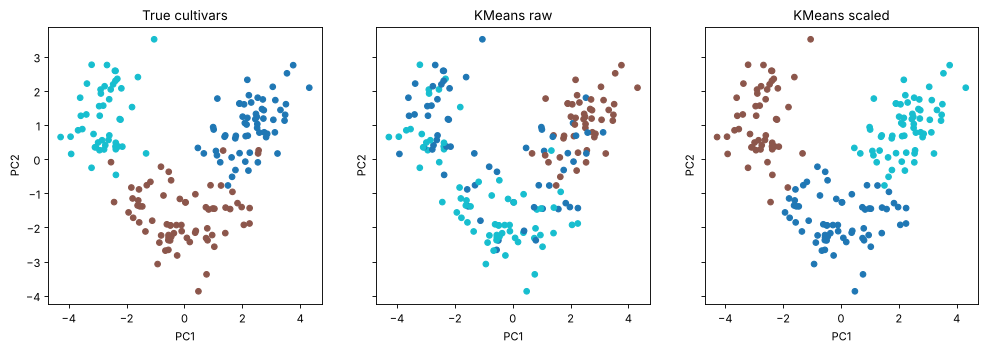

In [ ]:
Z = PCA(n_components=2, random_state=SEED).fit_transform(Xws)
fig, ax = plt.subplots(1, 3, figsize=(15,4.5), sharex=True, sharey=True)
for a_, l, t in zip(ax, [yw, mw_raw.labels_, mw_sc.labels_], ['True cultivars', 'KMeans raw', 'KMeans scaled']):
    a_.scatter(Z[:,0], Z[:,1], c=l, cmap='tab10', s=25)
    a_.set_title(t); a_.set_xlabel('PC1'); a_.set_ylabel('PC2')
plt.show()


**Questions** (answer with your own numbers)

(a) What happened when only the unit of Income changed? Explain it with the distance formula (which feature controls the distance now?).

(b) On the Wine data which feature dominated the raw distance and how big is its standard deviation compared with the others? What were the ARI values raw vs scaled?

(c) The silhouette was higher on the raw Wine data although the clustering was worse. Explain why a silhouette can mislead here and why comparing it between raw and scaled data is not fair.

(d) In a real project with no labels, how will you decide whether to scale? Write your rule in one or two sentences.



Your answers:

(a) The clusters changed (ARI between raw k$ and raw dollars is only 0.49). Now income is 15000 to 137000 and age is only 18 to 70, so income decides almost all of the distance and age is ignored.

(b) Proline dominated. Its std is 314 while magnesium is 14.2 and the smallest is 0.12 (nonflavanoid phenols). ARI against true cultivar was 0.371 for raw and 0.898 for scaled.

(c) Raw silhouette was 0.571 and scaled was 0.285. On raw data the distance is basically only proline, so the groups look well separated in that one feature and the silhouette is high, but they do not match the real cultivars. Silhouette is measured in a different space for each, so comparing raw and scaled is not fair.

(d) Scale when features have different units or very different ranges, which is most of the time. Do not scale only when all features are in the same unit and the size difference really means something.


---

## Part 5 — Outliers and Anomalies (20 minutes)

The lecture said 'one extreme point drags a centroid'. You will add one extreme customer, see the damage, and then catch it with a distance rule (the anomaly detection idea from the lecture).

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Outlier | A point far away from all the others. K-Means uses means and squared distances, so one outlier has a big effect. | `A very large distance to the nearest centroid.` |
| Distance to own centroid | How far a point is from the centre of its cluster. Large = the point does not fit any group well. | `model.transform(X).min(axis=1)` |
| mean + 3 std rule | Flag a point if its distance is larger than the mean distance plus 3 standard deviations. | `d > d.mean() + 3*d.std()` |
| Anomaly detection | Using the clusters to find strange points (far from every centroid). | `Sort by the distance column.` |


### Task 5.1 — One extreme customer

Add one extra row to X2: Income = 400, Spending = 99. Use K = 5 on Income and Spending.

1. Fit KMeans (n_init=10, random_state=SEED) without and with the extra customer.
2. Print the cluster sizes, the centroids (sorted by income) and the ARI between the two results on the original 200 customers.
3. Draw the two clusterings side by side.


In [ ]:
X2e = np.vstack([X2, [400, 99]])
m_a = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
m_b = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2e)
print('sizes without extra:', np.bincount(m_a.labels_))
print('sizes with extra   :', np.bincount(m_b.labels_))
print('centroids without extra (sorted by income):')
print(m_a.cluster_centers_[np.argsort(m_a.cluster_centers_[:,0])].round(1))
print('centroids with extra (sorted by income):')
print(m_b.cluster_centers_[np.argsort(m_b.cluster_centers_[:,0])].round(1))
print('ARI on original 200:', round(adjusted_rand_score(m_a.labels_, m_b.labels_[:200]),4))


sizes without extra: [81 39 22 35 23]
sizes with extra   : [100   1  23  39  38]
centroids without extra (sorted by income):
[[25.7 79.4]
 [26.3 20.9]
 [55.3 49.5]
 [86.5 82.1]
 [88.2 17.1]]
centroids with extra (sorted by income):
[[ 26.3  20.9]
 [ 48.3  56.5]
 [ 86.5  82.1]
 [ 87.   18.6]
 [400.   99. ]]
ARI on original 200: 0.7532


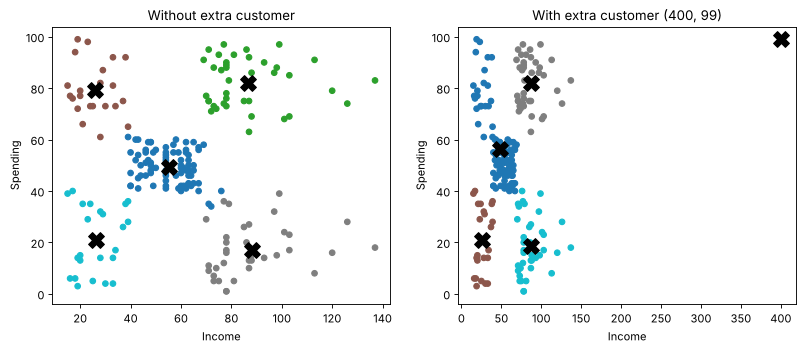

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12,4.5))
ax[0].scatter(X2[:,0], X2[:,1], c=m_a.labels_, cmap='tab10', s=25)
ax[0].scatter(m_a.cluster_centers_[:,0], m_a.cluster_centers_[:,1], c='black', marker='X', s=200)
ax[0].set_title('Without extra customer')
ax[1].scatter(X2e[:,0], X2e[:,1], c=m_b.labels_, cmap='tab10', s=25)
ax[1].scatter(m_b.cluster_centers_[:,0], m_b.cluster_centers_[:,1], c='black', marker='X', s=200)
ax[1].set_title('With extra customer (400, 99)')
for a_ in ax:
    a_.set_xlabel('Income'); a_.set_ylabel('Spending')
plt.show()


### Task 5.2 — Catch it and repair

Use the model fitted on the original 200 customers.

1. Compute every customer's distance to its nearest centroid, and the distance of the extra customer to the nearest centroid of the same model.
2. Apply the rule mean + 3 std (mean and std from the 200 real customers). How many real customers are flagged? Is the extra customer flagged?
3. Show the 5 real customers that are farthest from their centroid (CustomerID, Age, Income, Spending, Cluster, Distance).
4. Remove all flagged points, refit K = 5 and report the cluster sizes and the ARI against the original model on the 200 customers (use predict).


In [ ]:
dist_all = m_a.transform(X2).min(axis=1)
d_extra = m_a.transform([[400, 99]]).min()
thr = dist_all.mean() + 3 * dist_all.std()
flag = dist_all > thr
print('threshold:', round(thr,2), ' extra distance:', round(d_extra,2))
print('real customers flagged:', flag.sum(), ' extra flagged:', d_extra > thr)
tmp = df.copy()
tmp['Cluster'] = m_a.labels_
tmp['Distance'] = dist_all
print(tmp.sort_values('Distance', ascending=False).head(5)[['CustomerID','Age','Income','Spending','Cluster','Distance']].round(2).to_string(index=False))
m_c = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2[~flag])
print('sizes after removing flagged:', np.bincount(m_c.labels_))
print('ARI vs original model (predict on 200):', round(adjusted_rand_score(m_a.labels_, m_c.predict(X2)),4))


threshold: 34.8  extra distance: 313.92
real customers flagged: 4  extra flagged: True
 CustomerID  Age  Income  Spending  Cluster  Distance
        200   30     137        83        1     50.47
        199   32     137        18        3     48.81
        198   32     126        74        1     40.29
        197   45     126        28        3     39.34
        196   35     120        79        1     33.61
sizes after removing flagged: [80 34 23 37 22]
ARI vs original model (predict on 200): 0.9847


**Questions** (answer with your own numbers)

(a) What did the single extreme customer do to the clusters? Which real groups were affected? Use sizes and centroids.

(b) How well did the rule detect the extra customer? The rule also flagged some real customers: are they mistakes in the data or something worth looking at? Look at their Income and Spending.

(c) Name two ways to deal with outliers and one risk of simply deleting them.



Your answers:

(a) The extra customer (400, 99) took one cluster all by itself (size 1). Because of this the real low-income/high-spending group and the mid group got merged into one big cluster of 100 (centroid about 48, 56). Cluster sizes changed from 81, 39, 22, 35, 23 to 100, 1, 23, 39, 38 and the ARI on the 200 real customers fell to 0.75.

(b) It detected the extra customer very well, its distance was 313.9 and the threshold was only 34.8. It also flagged 4 real customers (IDs 197 to 200) with income 126-137k. They are not mistakes, they are very rich customers at the edge of the data and worth looking at.

(c) We can cap or transform the extreme values, or use a method that is less sensitive to outliers, or keep them as a separate group. The risk of deleting is that we lose real and maybe very valuable customers, like the rich ones here.


---

## Part 6 — From Clusters to Customer Segments (25 minutes)

Clusters are numbers (0, 1, 2 ...). The business needs names and actions. Cluster numbers are arbitrary labels: cluster 3 in one run has no meaning by itself. Use the original 200 customers and K = 5 on Income and Spending (random_state=SEED).

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Cluster profile | The average of every feature inside each cluster, plus the cluster size. This is how you read what a cluster means. | `df.groupby('Cluster').agg(...)` |
| Segment | A cluster with a name and an action, for example 'High income / Low spending'. | `df['Cluster'].map(names)` |
| Crosstab | Counts or percentages of one category inside another (Gender inside Segment). | `pd.crosstab(a, b, normalize='index')` |


### Task 6.1 — Profile and name the segments

Make the clustering readable for a manager.

1. Add the cluster number to the data. Build a profile table: number of customers, mean Age, mean Income, mean Spending and % female for each cluster, sorted by Income.
2. Create segment names with a small rule (Income below 40 = Low, 70 or more = High, otherwise Mid; Spending below 35 = Low, 65 or more = High, otherwise Mid). Print the size of each segment.


In [ ]:
df['Cluster'] = m5.labels_
df['Female'] = (df['Gender'] == 'Female').astype(int)
prof = df.groupby('Cluster').agg(Customers=('Age','size'), Age=('Age','mean'), Income=('Income','mean'),
                                 Spending=('Spending','mean'), PctFemale=('Female','mean'))
prof['PctFemale'] = prof['PctFemale'] * 100
prof = prof.sort_values('Income')
print(prof.round(1))


         Customers   Age  Income  Spending  PctFemale
Cluster                                              
2               22  25.3    25.7      79.4       59.1
4               23  45.2    26.3      20.9       60.9
0               81  42.7    55.3      49.5       59.3
1               39  32.7    86.5      82.1       53.8
3               35  41.1    88.2      17.1       45.7


In [ ]:
def lvl_inc(v):
    return 'Low' if v < 40 else ('High' if v >= 70 else 'Mid')
def lvl_sp(v):
    return 'Low' if v < 35 else ('High' if v >= 65 else 'Mid')
names = {k: lvl_inc(r.Income) + ' income / ' + lvl_sp(r.Spending) + ' spending' for k, r in prof.iterrows()}
df['Segment'] = df['Cluster'].map(names)
print(names)
print(df['Segment'].value_counts())


{2: 'Low income / High spending', 4: 'Low income / Low spending', 0: 'Mid income / Mid spending', 1: 'High income / High spending', 3: 'High income / Low spending'}
Segment
Mid income / Mid spending      81
High income / High spending    39
High income / Low spending     35
Low income / Low spending      23
Low income / High spending     22
Name: count, dtype: int64


### Task 6.2 — Does Gender matter? Does Age matter?

Gender and Age were not used in the clusters. Check whether they would add something.

1. Show the % of women in each segment and the overall %.
2. Scale Age, Income and Spending together and print the average silhouette for K = 2 to 8.


In [ ]:
print('% women per segment:')
print((df.groupby('Segment')['Female'].mean() * 100).round(1))
print('overall % women:', round(df['Female'].mean() * 100, 1))
X3 = StandardScaler().fit_transform(df[['Age','Income','Spending']])
r3 = []
for k in range(2, 9):
    m = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X3)
    r3.append([k, silhouette_score(X3, m.labels_)])
r3 = pd.DataFrame(r3, columns=['K','Silhouette'])
print(r3.round(4).to_string(index=False))


% women per segment:
Segment
High income / High spending    53.8
High income / Low spending     45.7
Low income / High spending     59.1
Low income / Low spending      60.9
Mid income / Mid spending      59.3
Name: Female, dtype: float64
overall % women: 56.0
 K  Silhouette
 2      0.3355
 3      0.3578
 4      0.4040
 5      0.4166
 6      0.4284
 7      0.4172
 8      0.4082


### Task 6.3 — A three-feature alternative

Cluster the scaled Age, Income and Spending with the best K from the table above.

1. Fit it, build its profile table (size, Age, Income, Spending) sorted by Age.
2. Print the ARI between this segmentation and your 2-feature K = 5 segmentation.


In [ ]:
bk = int(r3.loc[r3['Silhouette'].idxmax(), 'K'])
print('best K:', bk)
m3 = KMeans(n_clusters=bk, n_init=10, random_state=SEED).fit(X3)
df['Cluster3'] = m3.labels_
p3 = df.groupby('Cluster3').agg(Customers=('Age','size'), Age=('Age','mean'), Income=('Income','mean'), Spending=('Spending','mean')).sort_values('Age')
print(p3.round(1))
print('ARI 3-feature vs 2-feature K=5:', round(adjusted_rand_score(df['Cluster'], df['Cluster3']), 4))


best K: 6
          Customers   Age  Income  Spending
Cluster3                                   
4                23  25.0    25.3      77.6
1                39  26.8    57.1      48.1
3                39  32.7    86.5      82.1
2                33  41.9    88.9      17.0
5                21  45.5    26.3      19.4
0                45  56.3    54.3      49.1
ARI 3-feature vs 2-feature K=5: 0.7002


**Questions** (answer with your own numbers)

(a) Give each of the 5 segments a short business name and one concrete action (an offer or a message). Use the numbers from your profile table.

(b) Which segment is the most valuable now and which one is the biggest opportunity? Why?

(c) Does Gender help to separate the segments? Quote the percentages.

(d) Does adding Age change the story? Which segmentation would you present and why? (Careful: silhouette values from different feature sets are not directly comparable.)



Your answers:

(a) Low income / High spending (22): Young Trendy Spenders, send new trend offers. Low income / Low spending (23): Budget Savers, give discount coupons. Mid / Mid (81): Average Shoppers, give loyalty points. High / High (39): VIP Customers, give early access and premium rewards. High income / Low spending (35): Rich but Careful, send personal luxury offers.

(b) Most valuable now is High income / High spending (39 customers, income 86.5k, spending 82). Biggest opportunity is High income / Low spending (35 customers, income 88k but spending only 17), because they can afford more but do not buy.

(c) Not really. Women are 53.8% to 61% in all segments against 56.0% overall, only High / Low is a bit lower at 45.7%.

(d) Age splits the mid group into a young one (age 27) and an older one (age 56), and best K becomes 6 (silhouette 0.4284), but ARI with the 2-feature result is 0.70 so the story is mostly the same. I would present the 2-feature K=5 because it is simpler and clearer, and use age only as extra info.


---

## Part 7 — Final Output and Wrap-Up (15 minutes)

Package your result like you would give it to a marketing team.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Deliverable | A file someone else can use without running your notebook. | `df.to_csv('customer_segments.csv', index=False)` |


### Task 7.1 — Save the segments

Create a CSV with CustomerID, Age, Gender, Income, Spending, Cluster and Segment.

1. Save it as customer_segments.csv and print the number of customers per segment.
2. Write a 6-8 line Executive Summary (Markdown): the K you chose and the evidence for it, the segments and their sizes, one action per segment (short), how you handled scaling and outliers, and one limitation.


In [ ]:
out = df[['CustomerID','Age','Gender','Income','Spending','Cluster','Segment']]
out.to_csv('customer_segments.csv', index=False)
print(out['Segment'].value_counts())
print(out.head())


Segment
Mid income / Mid spending      81
High income / High spending    39
High income / Low spending     35
Low income / Low spending      23
Low income / High spending     22
Name: count, dtype: int64
   CustomerID  Age  Gender  ...  Spending  Cluster                     Segment
0           1   19    Male  ...        39        4   Low income / Low spending
1           2   21    Male  ...        81        2  Low income / High spending
2           3   20  Female  ...         6        4   Low income / Low spending
3           4   23  Female  ...        77        2  Low income / High spending
4           5   31  Female  ...        40        4   Low income / Low spending

[5 rows x 7 columns]


Executive Summary

I chose K = 5 using Income and Spending because the elbow bends at K=5 (inertia drops 29231 from 4 to 5 but only 7215 from 5 to 6) and silhouette is highest at K=5 (0.554).
The segments are Mid/Mid (81), High/High (39), High income/Low spending (35), Low/Low (23) and Low income/High spending (22).
Actions: loyalty points for Mid/Mid, VIP early access for High/High, luxury offers for High/Low, coupons for Low/Low and trend offers for Low/High.
Scaling was not needed for the 2 features since both are on similar scale, but we saw on Wine that scaling is very important when units are different.
One extreme customer broke the clusters (ARI 0.75), the mean + 3 std rule caught it and 4 real rich customers were also flagged but they are real so I kept them.
Limitation: only 200 customers and 2-3 features, and K-Means only makes round groups and gives different answers with bad starts.


**Questions** (answer with your own numbers)

(a) What was the most surprising result in this lab?

(b) If you had one more hour, what would you try next?



Your answers:

(a) The most surprising thing was that the silhouette was higher on the raw Wine data (0.57) even though the clustering was worse (ARI 0.37 vs 0.90 when scaled). Also that one customer could change the clusters so much.

(b) I would try DBSCAN or hierarchical clustering to compare with K-Means, and add more features like Age with proper scaling.


---